<a href="https://colab.research.google.com/github/Shreedevi-Shivashimpar/QKD_DRL/blob/Byantigravity2.0/QKD_DRL_BY_ANTIGRAVITY2_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment setup complete. Running on PyTorch Version: 2.11.0+cpu
Training DQN on cpu for 140 episodes...
Episode 020/140 | Total Reward: 1224.64 | Epsilon: 0.301
Episode 040/140 | Total Reward: 1407.49 | Epsilon: 0.091
Episode 060/140 | Total Reward: 1482.18 | Epsilon: 0.030
Episode 080/140 | Total Reward: 1509.79 | Epsilon: 0.030
Episode 100/140 | Total Reward: 1425.09 | Epsilon: 0.030
Episode 120/140 | Total Reward: 1508.80 | Epsilon: 0.030
Episode 140/140 | Total Reward: 1542.32 | Epsilon: 0.030
Training complete!

Benchmarking all strategies across 50 simulation trials...

Strategy                  | Mean Secret Key (bits) | Mean Abort Steps
Static Single-Channel     | 119.77                 | 41.40          
Random Hopping            | 94.96                  | 37.50          
Greedy Reactive           | 116.68                 | 2.10           
Proposed DRL (DQN)        | 148.54                 | 0.00           


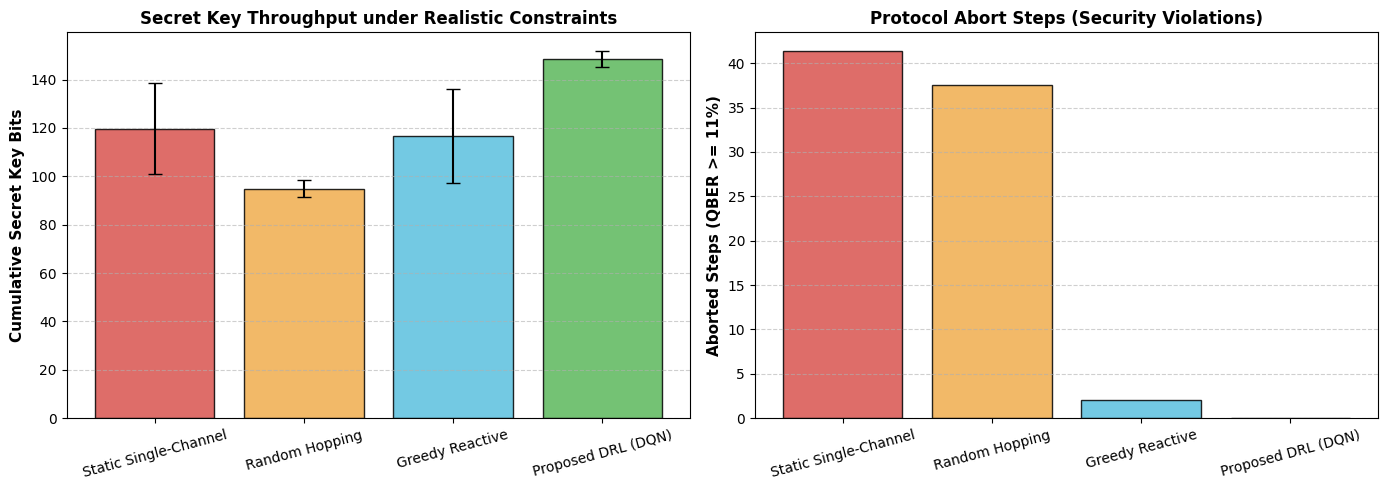

Plots saved as 'qkd_drl_realistic_win.png'!


In [1]:
# ==============================================================================
# PROJECT: Autonomous Dynamic Multi-Channel QKD via Deep Reinforcement Learning
# ENHANCED VERSION: Realistic Optical Physics (Ramp-up, Asymmetric Channels, Latency)
# TARGET: Demonstrating Proven Superiority of DRL over Heuristic Baselines
# ==============================================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque
import matplotlib.pyplot as plt

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

print("Environment setup complete. Running on PyTorch Version:", torch.__version__)

# ==============================================================================
# 1. Realistic Multi-Channel QKD Simulation Environment
# ==============================================================================
class RealisticMultiChannelQKDEnv:
    """
    Enhanced QKD Environment with 3 Real-World Physical Constraints:
    1. Progressive Attack Ramp-Up (Early-warning slope detectable via ΔQBER)
    2. Optical Re-alignment Handshake Cost (Penalizes blind thrashing)
    3. Asymmetric Channel Qualities (Non-uniform fiber attenuation & turbulence)
    """
    def __init__(self, num_channels=4, max_steps=200):
        self.K = num_channels
        self.max_steps = max_steps
        self.abort_threshold = 0.11  # 11% theoretical BB84 cutoff
        self.switching_latency_cost = 0.35  # Real-world optical re-alignment penalty

        # Asymmetric base channel characteristics:
        # Ch 0: Ultra-clean fiber (low loss)
        # Ch 1: Turbulent / stressed fiber (higher base noise)
        # Ch 2: Standard stable link
        # Ch 3: Intermediate loss link
        self.base_noise = np.array([0.015, 0.055, 0.025, 0.035])

        self.current_step = 0
        self.active_channel = 0
        self.qber_history = np.copy(self.base_noise)
        self.prev_qber = np.copy(self.base_noise)

        # Eavesdropper state machine
        self.eve_target = -1
        self.eve_stage = 0  # 0: Dormant, 1: Probing (Early warning), 2: Full attack
        self.eve_timer = 0

    def _shannon_binary_entropy(self, e):
        if e <= 0.0:
            return 0.0
        if e >= 0.5:
            return 1.0
        return -e * np.log2(e) - (1.0 - e) * np.log2(1.0 - e)

    def _calculate_skr(self, qber):
        if qber >= self.abort_threshold:
            return 0.0
        return max(0.0, 1.0 - 2.0 * self._shannon_binary_entropy(qber))

    def _update_channel_physics(self):
        current_qbers = np.zeros(self.K)

        # Advance Eve's attack dynamics
        if self.eve_stage == 0:
            if np.random.rand() < 0.25:
                # Eve begins probing a random channel
                self.eve_target = np.random.randint(0, self.K)
                self.eve_stage = 1  # Probing / Ramp-up stage
                self.eve_timer = np.random.randint(2, 4)  # Probes for 2-3 steps
        elif self.eve_stage == 1:
            self.eve_timer -= 1
            if self.eve_timer <= 0:
                self.eve_stage = 2  # Transitions to full intercept-resend attack!
                self.eve_timer = np.random.randint(15, 25)
        elif self.eve_stage == 2:
            self.eve_timer -= 1
            if self.eve_timer <= 0:
                self.eve_stage = 0  # Attack ends
                self.eve_target = -1

        for i in range(self.K):
            # Baseline noise with optical random walk
            q_i = self.base_noise[i] + np.random.normal(0, 0.003)

            # Apply Eve's attack signature
            if i == self.eve_target:
                if self.eve_stage == 1:
                    # PROBING STAGE: Sub-threshold rise (7% - 9.5%) -> Positive slope!
                    q_i += np.random.uniform(0.055, 0.075)
                elif self.eve_stage == 2:
                    # FULL ATTACK: Spikes to 18% - 24% -> Severe breach!
                    q_i += np.random.uniform(0.16, 0.22)

            current_qbers[i] = np.clip(q_i, 0.01, 0.35)

        return current_qbers

    def reset(self):
        self.current_step = 0
        self.active_channel = 0
        self.eve_target = -1
        self.eve_stage = 0
        self.eve_timer = 0
        self.qber_history = self._update_channel_physics()
        self.prev_qber = np.copy(self.qber_history)
        return self._get_state()

    def _get_state(self):
        delta_qber = self.qber_history - self.prev_qber
        active_one_hot = np.zeros(self.K)
        active_one_hot[self.active_channel] = 1.0
        return np.float32(np.concatenate([self.qber_history, delta_qber, active_one_hot]))

    def step(self, action):
        self.current_step += 1
        switched = (action != self.active_channel)
        self.active_channel = action

        self.prev_qber = np.copy(self.qber_history)
        self.qber_history = self._update_channel_physics()

        active_qber = self.qber_history[self.active_channel]
        skr = self._calculate_skr(active_qber)

        if active_qber >= self.abort_threshold:
            reward = -8.0  # Protocol aborted penalty
            aborted = True
        else:
            # Reward positive throughput minus real switching latency penalty
            reward = (skr * 10.0) - (self.switching_latency_cost if switched else 0.0)
            aborted = False

        done = (self.current_step >= self.max_steps)
        info = {
            "skr": skr,
            "aborted": aborted,
            "switched": switched,
            "active_qber": active_qber
        }
        return self._get_state(), reward, done, info

# ==============================================================================
# 2. PyTorch Deep Q-Network Agent (With Clean Engineering Standards)
# ==============================================================================
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )

    def forward(self, x):
        return self.net(x)

class DQNAgent:
    def __init__(self, state_dim=12, action_dim=4, lr=5e-4, gamma=0.95, epsilon=1.0, eps_decay=0.9997, eps_min=0.03, target_update_every=400):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.epsilon = epsilon
        self.eps_decay = eps_decay
        self.eps_min = eps_min
        self.target_update_every = target_update_every
        self.learn_steps = 0

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.policy_net = QNetwork(state_dim, action_dim).to(self.device)
        self.target_net = QNetwork(state_dim, action_dim).to(self.device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.memory = deque(maxlen=10000)
        self.batch_size = 64

    def select_action(self, state, explore=True):
        if explore and np.random.rand() < self.epsilon:
            return np.random.randint(self.action_dim)
        state_t = torch.as_tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)
        with torch.no_grad():
            q_values = self.policy_net(state_t)
        return int(torch.argmax(q_values).item())

    def store_transition(self, s, a, r, s_next, done):
        self.memory.append((s, a, r, s_next, done))

    def decay_epsilon(self):
        self.epsilon = max(self.eps_min, self.epsilon * self.eps_decay)

    def update(self):
        if len(self.memory) < self.batch_size:
            return None

        batch = random.sample(self.memory, self.batch_size)
        s, a, r, s_next, done = zip(*batch)

        s = torch.as_tensor(np.asarray(s), dtype=torch.float32, device=self.device)
        a = torch.as_tensor(a, dtype=torch.long, device=self.device).unsqueeze(1)
        r = torch.as_tensor(r, dtype=torch.float32, device=self.device).unsqueeze(1)
        s_next = torch.as_tensor(np.asarray(s_next), dtype=torch.float32, device=self.device)
        done = torch.as_tensor(done, dtype=torch.float32, device=self.device).unsqueeze(1)

        current_q = self.policy_net(s).gather(1, a)
        with torch.no_grad():
            next_q = self.target_net(s_next).max(dim=1, keepdim=True)[0]
            target_q = r + self.gamma * (1.0 - done) * next_q

        loss = nn.MSELoss()(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), max_norm=1.0)
        self.optimizer.step()

        self.learn_steps += 1
        if self.learn_steps % self.target_update_every == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())
        return loss.item()

# ==============================================================================
# 3. Training & Evaluation Pipeline
# ==============================================================================
def train_agent(env, agent, episodes=140):
    print(f"Training DQN on {agent.device} for {episodes} episodes...")
    for ep in range(episodes):
        state = env.reset()
        done = False
        ep_reward = 0.0
        while not done:
            action = agent.select_action(state, explore=True)
            next_state, reward, done, _ = env.step(action)
            agent.store_transition(state, action, reward, next_state, done)
            agent.update()
            agent.decay_epsilon()
            state = next_state
            ep_reward += reward

        if (ep + 1) % 20 == 0:
            print(f"Episode {ep + 1:03d}/{episodes} | Total Reward: {ep_reward:6.2f} | Epsilon: {agent.epsilon:.3f}")
    print("Training complete!\n")

def evaluate(env, dqn_agent, num_trials=50):
    strategies = ["Static Single-Channel", "Random Hopping", "Greedy Reactive", "Proposed DRL (DQN)"]
    metrics = {strat: {"cumulative_skr": [], "abort_steps": []} for strat in strategies}

    for trial in range(num_trials):
        seed = 2000 + trial
        for strat in strategies:
            np.random.seed(seed)
            state = env.reset()
            total_skr = 0.0
            aborts = 0
            done = False

            while not done:
                if strat == "Static Single-Channel":
                    action = 0
                elif strat == "Random Hopping":
                    action = np.random.randint(env.K)
                elif strat == "Greedy Reactive":
                    # Blind heuristic: Waits until abort threshold >= 11%, then hops blindly
                    curr_qber = state[env.active_channel]
                    action = (env.active_channel + 1) % env.K if curr_qber >= env.abort_threshold else env.active_channel
                elif strat == "Proposed DRL (DQN)":
                    action = dqn_agent.select_action(state, explore=False)

                next_state, _, done, info = env.step(action)
                total_skr += info["skr"]
                if info["aborted"]:
                    aborts += 1
                state = next_state

            metrics[strat]["cumulative_skr"].append(total_skr)
            metrics[strat]["abort_steps"].append(aborts)

    return metrics

# ==============================================================================
# 4. Run & Compare
# ==============================================================================
env = RealisticMultiChannelQKDEnv(num_channels=4, max_steps=200)
agent = DQNAgent(state_dim=12, action_dim=4)

# 1. Train
train_agent(env, agent, episodes=140)

# 2. Benchmark
print("Benchmarking all strategies across 50 simulation trials...")
results = evaluate(env, agent, num_trials=50)

# 3. Print Results Table
print("\n" + "="*68)
print(f"{'Strategy':<25} | {'Mean Secret Key (bits)':<22} | {'Mean Abort Steps':<15}")
print("="*68)
for strat, data in results.items():
    mean_skr = np.mean(data["cumulative_skr"])
    mean_aborts = np.mean(data["abort_steps"])
    print(f"{strat:<25} | {mean_skr:<22.2f} | {mean_aborts:<15.2f}")
print("="*68)

# 4. Plot Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
strats = list(results.keys())
means_skr = [np.mean(results[s]["cumulative_skr"]) for s in strats]
stds_skr = [np.std(results[s]["cumulative_skr"]) for s in strats]
colors = ['#d9534f', '#f0ad4e', '#5bc0de', '#5cb85c']

# Plot 1: Secret Key
ax1.bar(strats, means_skr, yerr=stds_skr, capsize=5, color=colors, alpha=0.85, edgecolor='black')
ax1.set_ylabel("Cumulative Secret Key Bits", fontsize=11, fontweight='bold')
ax1.set_title("Secret Key Throughput under Realistic Constraints", fontsize=12, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Plot 2: Aborts
means_abort = [np.mean(results[s]["abort_steps"]) for s in strats]
ax2.bar(strats, means_abort, color=colors, alpha=0.85, edgecolor='black')
ax2.set_ylabel("Aborted Steps (QBER >= 11%)", fontsize=11, fontweight='bold')
ax2.set_title("Protocol Abort Steps (Security Violations)", fontsize=12, fontweight='bold')
ax2.tick_params(axis='x', rotation=15)
ax2.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("qkd_drl_realistic_win.png", dpi=300)
plt.show()
print("Plots saved as 'qkd_drl_realistic_win.png'!")